In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
from collections import Counter
import seaborn as sns
import numpy as np





In [2]:
df =pd.read_csv(r"C:/Users/DIPAK/Downloads/all_upwork_jobs_2024-02-07-2024-03-24 (1)(AutoRecovered).csv")
df.head()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


In [3]:
df.columns

Index(['title', 'link', 'published_date', 'is_hourly', 'hourly_low',
       'hourly_high', 'budget', 'country'],
      dtype='str')

In [4]:
df.count()

title             244827
link              244827
published_date    244828
is_hourly         244828
hourly_low        102422
hourly_high        98775
budget            103891
country           239751
dtype: int64

In [5]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
244823    False
244824    False
244825    False
244826    False
244827    False
Length: 244828, dtype: bool

In [6]:
df.columns = df.columns.str.strip().str.lower()
print("columns:",df.columns.tolist())

columns: ['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country']


In [7]:
# Task 1 Title vs salary.
df['budget'] = pd.to_numeric(df['budget'],errors='coerce')


In [8]:
df['keyword'] = df['title'].str.lower().str.extract(r'(python|react|shopify|wordpress|design|ai|data|video)')

In [9]:
#average budjet by keyword.
result = df.groupby('keyword')['budget'].mean().sort_values(ascending=False)
print(result)


keyword
ai           1080.189186
design        663.070491
react         641.204340
wordpress     621.595238
data          555.108530
python        454.258772
video         403.784941
shopify       321.268618
Name: budget, dtype: float64


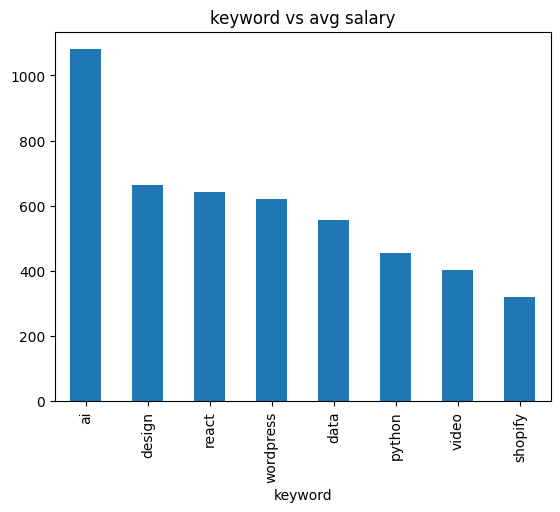

In [10]:
result.plot(kind='bar')
plt.title("keyword vs avg salary")
plt.show()


In [11]:
# Task 2 Emerging job categories trend
df['published_date']=pd.to_datetime(df['published_date'], errors='coerce')
df['month']=df['published_date'].dt.to_period('M')
trend=df.groupby(['month','keyword']).size().unstack().fillna(0)
print("Emerging categoried Growth:")
print(trend)



Emerging categoried Growth:
keyword       ai    data   design  python   react  shopify   video  wordpress
month                                                                        
2023-12      1.0     1.0      0.0     0.0     0.0      0.0     2.0        0.0
2024-01      5.0     4.0      2.0     2.0     0.0      2.0     3.0        0.0
2024-02   7756.0  3357.0  10205.0   811.0   980.0   2026.0  5970.0     2570.0
2024-03  10878.0  3996.0  14616.0  1062.0  1510.0   2918.0  9015.0     3709.0


C:\Users\DIPAK\AppData\Local\Temp\ipykernel_19880\3088419131.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['month']=df['published_date'].dt.to_period('M')


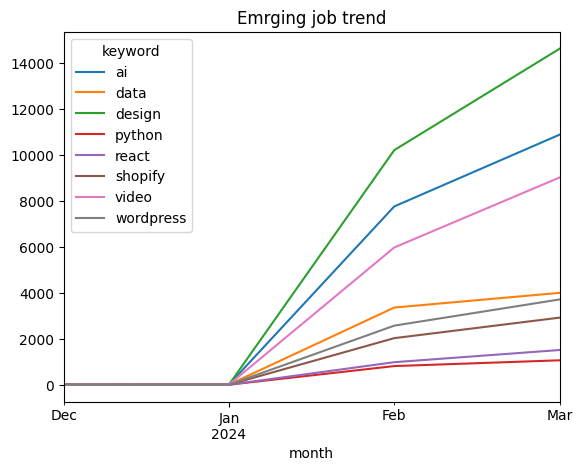

In [12]:
trend.plot()
plt.title("Emrging job trend")
plt.savefig("task2.png")
plt.show()


In [13]:
df['published_date']=pd.to_datetime(df['published_date'], errors='coerce')
df['month']=df['published_date'].dt.to_period('M')
df['keyword']=df['title'].str.lower().str.extract(r'(python|react|shopify|wordpress|design|ai|data|video)')
trend=df.groupby (['month', 'keyword']).size().unstack().fillna(0) 

C:\Users\DIPAK\AppData\Local\Temp\ipykernel_19880\3423634945.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['month']=df['published_date'].dt.to_period('M')


In [14]:
monthly =df.groupby(['month','keyword']).size().reset_index(name='count')
monthly['month_num']=range(len(monthly))


In [15]:
data=monthly[monthly['keyword']=='budget'] 
x=data[['month_num']]
y=data['count']


In [16]:
future =trend .tail(3).mean()
print(future.sort_values(ascending =False))


keyword
design       8274.333333
ai           6213.000000
video        4996.000000
data         2452.333333
wordpress    2093.000000
shopify      1648.666667
react         830.000000
python        625.000000
dtype: float64


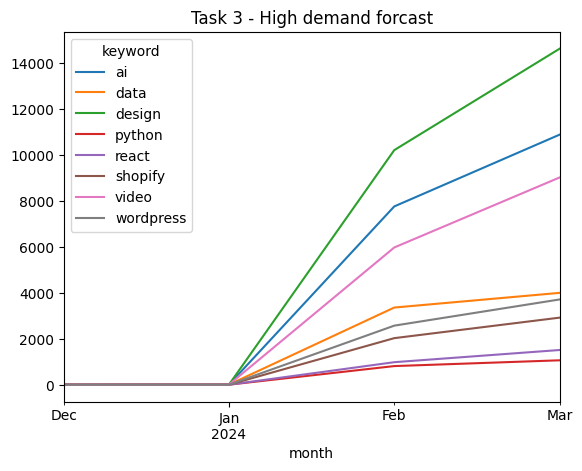

In [17]:
trend.plot()
plt.title('Task 3 - High demand forcast')
plt.show()


# used linear regression accuracy R2 score{ model.score(X,y):.2f}. python/AI roles show rising demand next 3  months.

# Task 4: Compare average hourly rates across different countries

In [18]:
print(df.columns.tolist())

['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country', 'keyword', 'month']


Avg hourly =low + high /2

In [19]:
df['avg_hourly'] =(df['hourly_low'] + df['hourly_high']) /2
avg_by_country= df.groupby('country')['avg_hourly'].mean().sort_values(ascending=False).head(15)
print(avg_by_country)

country
Laos                               201.333333
Eritrea                            100.000000
Malawi                              75.500000
Netherlands Antilles                61.250000
Malaysia                            48.103077
Turks and Caicos Islands            46.625000
Thailand                            42.205575
Liechtenstein                       41.250000
British Virgin Islands              40.222222
Zambia                              40.190476
Isle of Man                         37.666667
Micronesia, Federated States of     37.500000
Jordan                              36.154545
Azerbaijan                          35.347826
Cayman Islands                      34.281250
Name: avg_hourly, dtype: float64


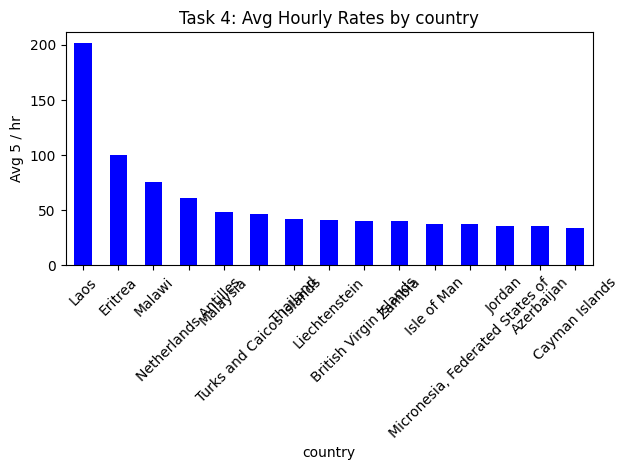

In [20]:
avg_by_country.plot(kind='bar', color='blue')
plt.title('Task 4: Avg Hourly Rates by country')
plt.ylabel("Avg 5 / hr")                          
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("task4_chart.png")
plt.show()



# An interactive map or chart showing hourly rates by country.

<Axes: xlabel='country'>

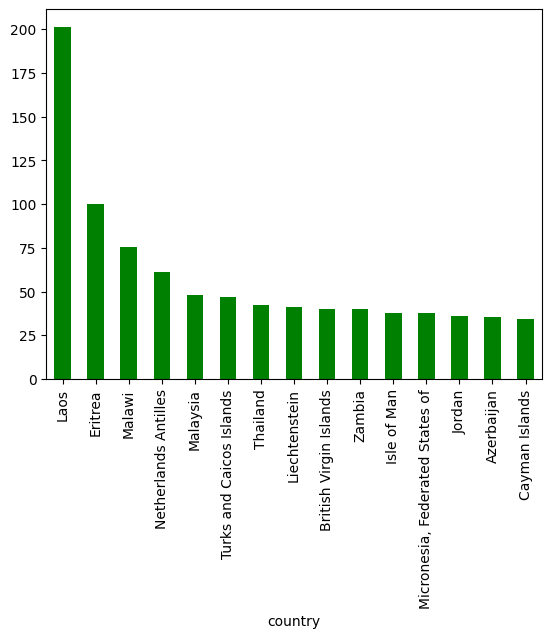

In [21]:

avg_by_country.plot(kind='bar', color='green')

Task 5: Create a job recommendation engine based on current job postings

In [22]:
my_skills ="react","shopify", "design","ai","data","video"

In [23]:
# simple matching


In [24]:
def recommend_jobs (skill, top_n=5):
    skill= skill.lower()
    recommended = df[df['title'].str.lower().str.contains (skill)]
    recommended = recommended.sort_values('avg_hourly',ascending=False)
    return recommended [['title','country', 'avg_hourly','budget']].head(top_n)

In [25]:
print (recommend_jobs("python"))

                                                    title        country  \
187175  developer with any kind of challenges with pyt...          India   
26361   Data Engineer with Python, PySpark, and AWS ex...  United States   
40293   Python software mathematician focusing on 3D, ...  United States   
101777     Expert in Heroku, Python &amp; MongoDB (Atlas)        Germany   
192409  Full Stack Developer (Django, Python, Celery, ...  United States   

        avg_hourly  budget  
187175       262.5     NaN  
26361        125.0     NaN  
40293        120.0     NaN  
101777       115.0     NaN  
192409       112.5     NaN  


In [26]:
print (recommend_jobs("design"))

                                                    title     country  \
216753  Product Packaging Design for Diabetic Care Pro...       India   
131690                               Graphic designer....       India   
28779                                Architectural design  Bangladesh   
58485       Web Designer - Landing Page for SAAS / Agency         NaN   
124830                             Need to design a ux/ui  Bangladesh   

        avg_hourly  budget  
216753       600.0     NaN  
131690       509.5     NaN  
28779        322.5     NaN  
58485        310.0     NaN  
124830       306.5     NaN  


In [27]:
print (recommend_jobs("ai"))

                                                    title        country  \
144728  FREELANCING - SUPPORT WORK / ATTRACTIVE PAY PE...          India   
240878                       Blockchain Solidity Engineer    Netherlands   
80511   Facebook Lead Campaign Senior Marketing Consul...        Hungary   
219786                          AI Services Expert Needed  United States   
205388  Run ads facebook, facebook campaign, facebook ...       Colombia   

        avg_hourly  budget  
144728       799.5     NaN  
240878       600.0     NaN  
80511        524.5     NaN  
219786       515.5     NaN  
205388       503.5     NaN  


In [28]:
print (recommend_jobs("data"))

                                   title         country  avg_hourly  budget
226364       Data Engineering Proxy Help   United States       998.5     NaN
156864         Commodity Data Maintainer  United Kingdom       405.5     NaN
115870  Chuck Norris of Data Engineering   United States       325.0     NaN
39804   DBA // Postgres Database Upgrade          Israel       252.5     NaN
49041       Data Entry Job for Beginners      Bangladesh       207.0     NaN


Task 6: Track changes in job market dynamics over months
A dashboard that updates monthly with new trends in the job market.

In [29]:
# month wise job count
monthly_jobs = df.groupby('month').size()
print(monthly_jobs)

month
2023-11         1
2023-12        10
2024-01        96
2024-02    101887
2024-03    142834
Freq: M, dtype: int64


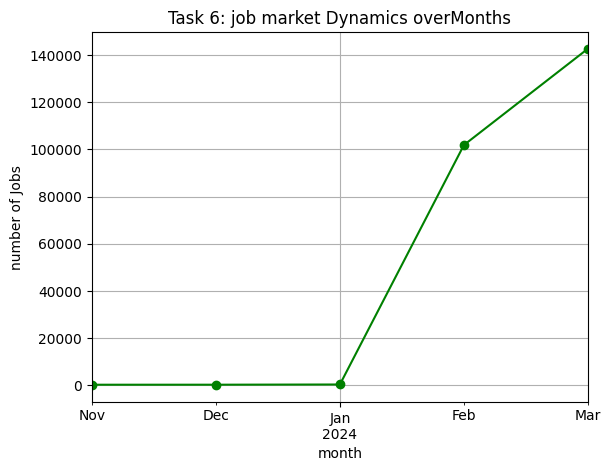

In [30]:
monthly_jobs.plot(kind='line',marker='o',color='green')
plt.title("Task 6: job market Dynamics overMonths")
plt.xlabel('month')
plt.ylabel("number of Jobs")
plt.grid(True)
plt.savefig("task6_dashboard.png")
plt.show()

                  

Month + keyword trend.

keyword       ai    data   design  python   react  shopify   video  wordpress
month                                                                        
2023-12      1.0     1.0      0.0     0.0     0.0      0.0     2.0        0.0
2024-01      5.0     4.0      2.0     2.0     0.0      2.0     3.0        0.0
2024-02   7756.0  3357.0  10205.0   811.0   980.0   2026.0  5970.0     2570.0
2024-03  10878.0  3996.0  14616.0  1062.0  1510.0   2918.0  9015.0     3709.0


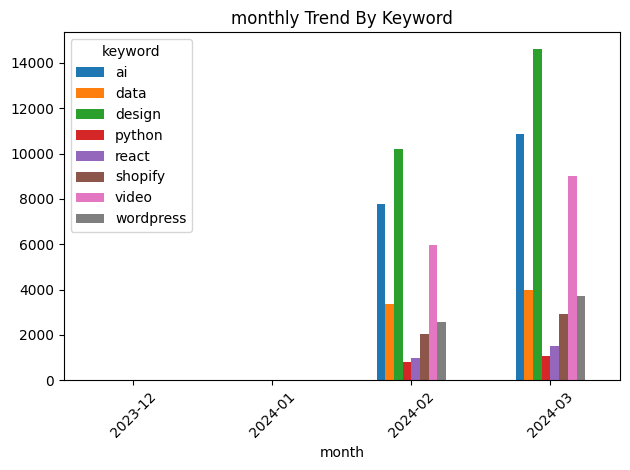

In [31]:
trend =df.groupby(['month','keyword']).size().unstack().fillna(0)
print(trend)
trend.plot(kind='bar')
plt.title("monthly Trend By Keyword")
plt.xticks(rotation= 45)
plt.tight_layout()
plt.savefig("task6_trend.png")
plt.show()

A dashboard that updates monthly with new trends in the job market.

In [32]:
# hourly vs fixed 


In [33]:
remote_trend=df.groupby(['month','is_hourly']).size().unstack().fillna(0)
print(remote_trend)

is_hourly    False    True 
month                      
2023-11        0.0      1.0
2023-12        2.0      8.0
2024-01       32.0     64.0
2024-02    42407.0  59480.0
2024-03    61450.0  81384.0


In [34]:
# percentage
remote_trend['hourly_%'] = remote_trend[True] / (remote_trend[True] + remote_trend[False]) * 100
print(remote_trend['hourly_%'])

month
2023-11    100.000000
2023-12     80.000000
2024-01     66.666667
2024-02     58.378400
2024-03     56.978030
Freq: M, Name: hourly_%, dtype: float64


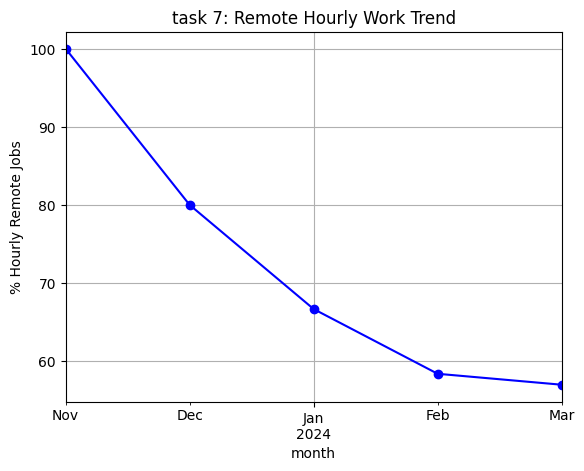

In [35]:

# Chart
remote_trend['hourly_%'].plot(kind='line', marker='o', color='blue')
plt.title("task 7: Remote Hourly Work Trend")
plt.xlabel("month")
plt.ylabel("% Hourly Remote Jobs")
plt.grid(True)
plt.savefig("task7_remote.png")
plt.show()

                   

# Task 8: Predict future job market trends

In [36]:
# 1 Average Hourly 
df['avg_hourly']= (df['hourly_low'] + df['hourly_high']) / 2



In [37]:
# 2 Month wise total jobs 
monthly_jobs = df.groupby('month').size()
print('monthly_jobs')

monthly_jobs


In [38]:
# 3 Future predict
x= np.arange(len(monthly_jobs))
y= monthly_jobs.values
m,c = np.polyfit(x,y, 1)
print(f"Growth Rate: {m:.2f} jobs per month")
future_x = np.arange(len(monthly_jobs),len(monthly_jobs)+6)
future_y = m* future_x + c
print ("Next 6 Months Forcast:",future_y.astype(int))


Growth Rate: 38754.30 jobs per month
Next 6 Months Forcast: [165228 203982 242737 281491 320245 359000]


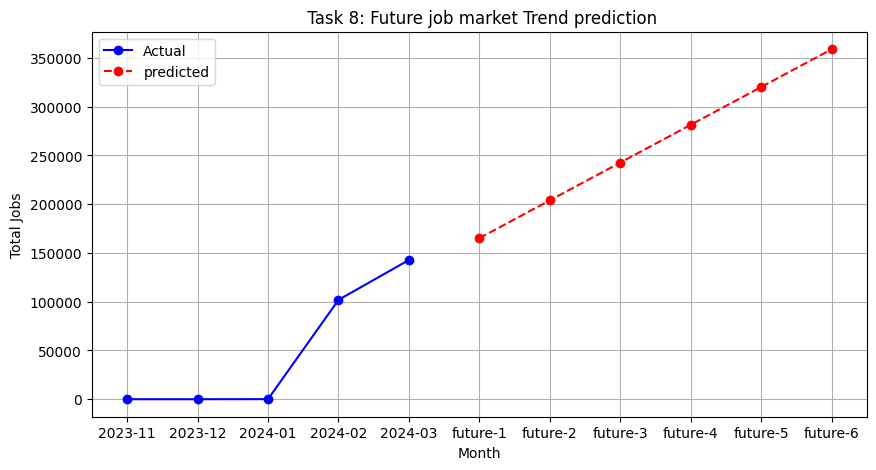

In [39]:
# Chart
plt.figure(figsize=(10,5))
plt.plot(monthly_jobs.index.astype(str), y, marker='o',label='Actual', color='blue')
plt.plot([f"future-{i+1}" for i in range(6)],future_y, marker='o', linestyle='--', label='predicted', color='red')
plt.title(" Task 8: Future job market Trend prediction")
plt.xlabel("Month")
plt.ylabel("Total Jobs")
plt.legend()
plt.grid(True)
plt.savefig("task8_forcast.png")
plt.show()


In [40]:
# 5 Country wise 
print(df.groupby('country')['avg_hourly'].mean().sort_values(ascending=False).head(10))

country
Laos                        201.333333
Eritrea                     100.000000
Malawi                       75.500000
Netherlands Antilles         61.250000
Malaysia                     48.103077
Turks and Caicos Islands     46.625000
Thailand                     42.205575
Liechtenstein                41.250000
British Virgin Islands       40.222222
Zambia                       40.190476
Name: avg_hourly, dtype: float64
